Библиотеки

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical


print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


Загрузка и иследование данных

Датасет о диабете
Размер: (768, 9)
Признаки: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Статистика:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.0

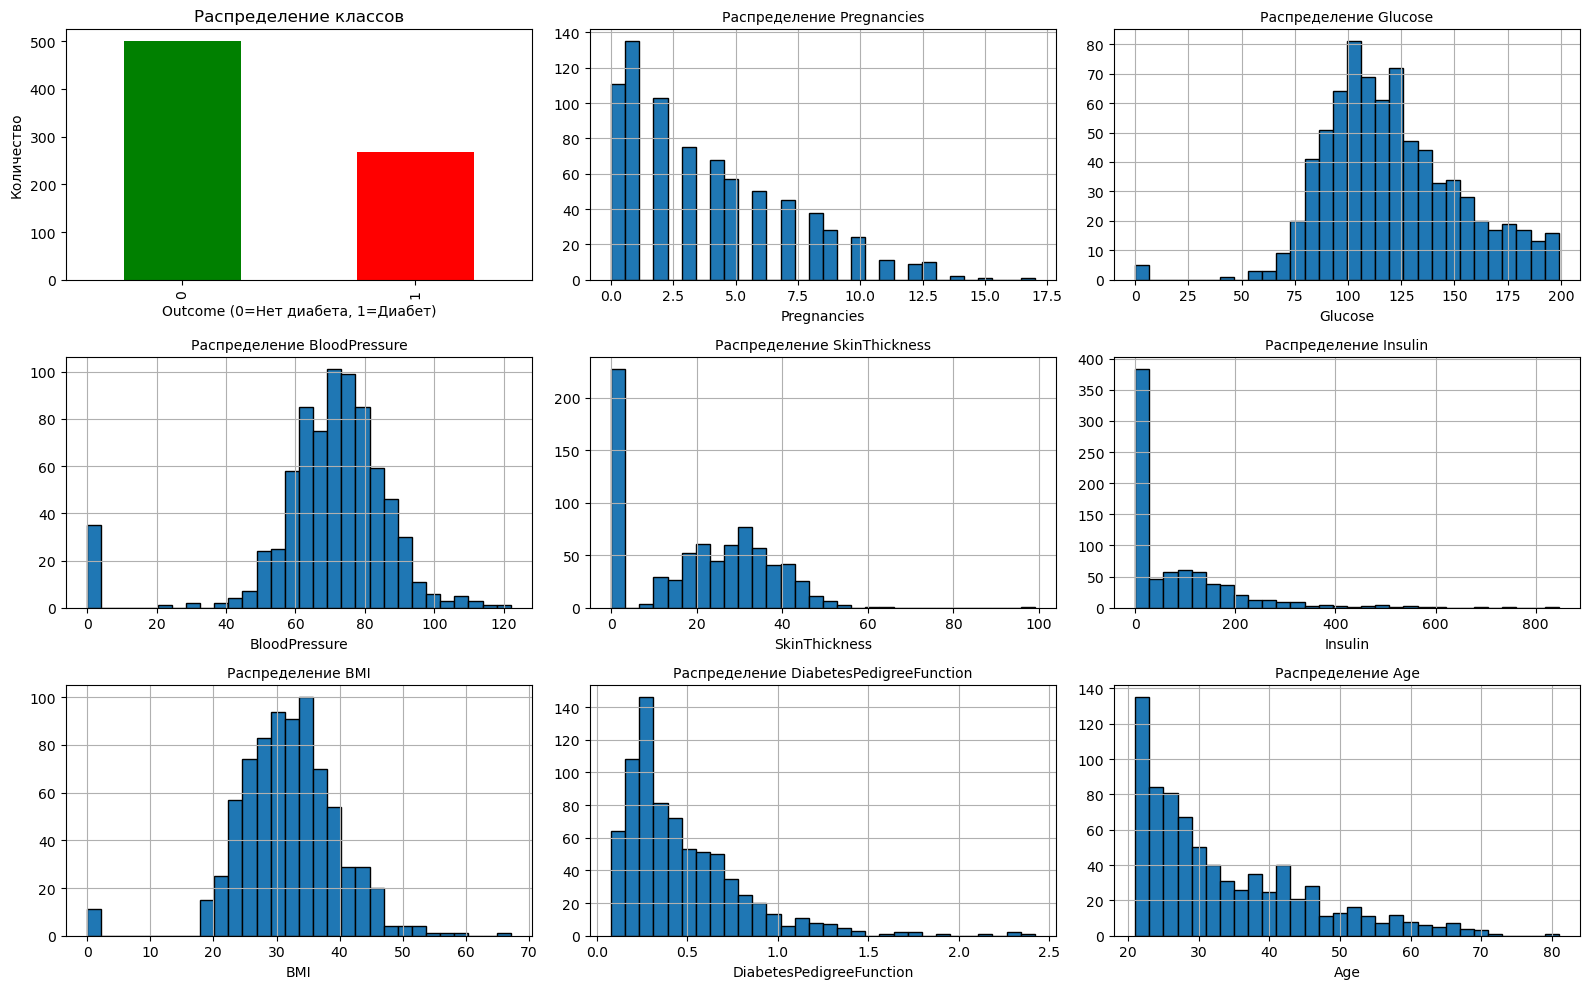

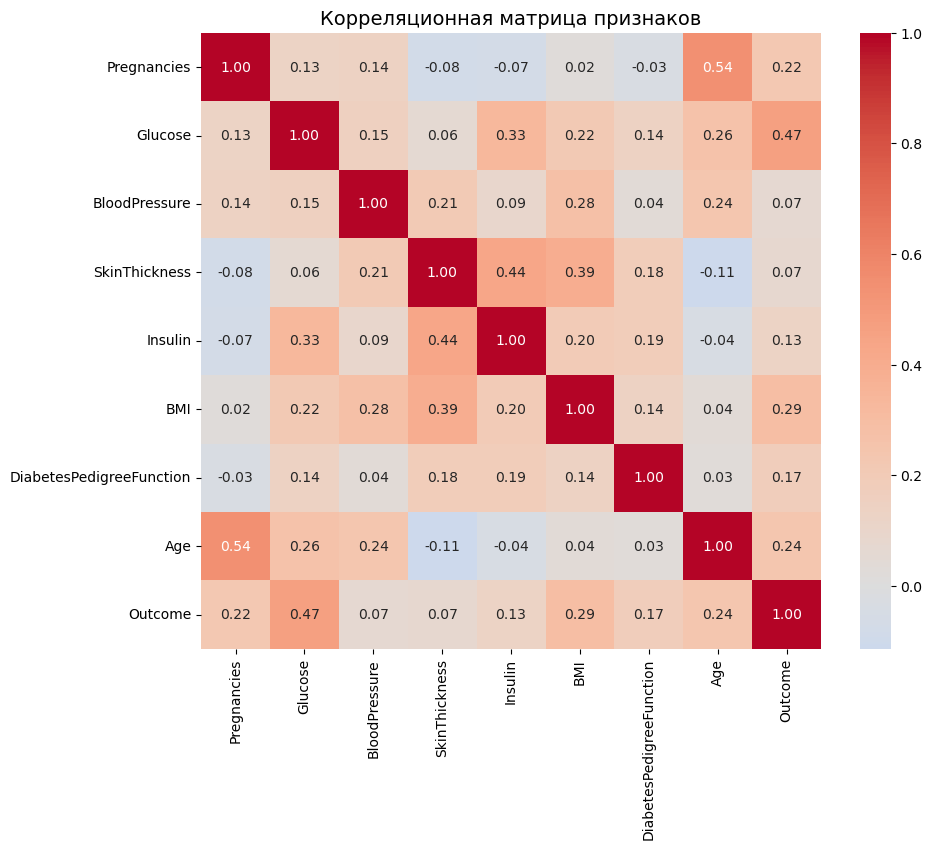

<Figure size 640x480 with 0 Axes>

In [ ]:

df = pd.read_csv('diabetes.csv')
print("Датасет о диабете")
print("="*50)
print(f"Размер: {df.shape}")
print(f"Признаки: {list(df.columns)}")
print(f"\nСтатистика:")
print(df.describe())


plt.figure(figsize=(16, 10))


plt.subplot(3, 3, 1)
df['Outcome'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Распределение классов', fontsize=12)
plt.xlabel('Outcome (0=Нет диабета, 1=Диабет)')
plt.ylabel('Количество')


feature_cols = df.columns[:-1]
for i, col in enumerate(feature_cols):
    plt.subplot(3, 3, i + 2)  
    df[col].hist(bins=30, edgecolor='black')
    plt.title(f'Распределение {col}', fontsize=10)
    plt.xlabel(col)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 8))
correlation = df.corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корреляционная матрица признаков', fontsize=14)
plt.show()



plt.tight_layout()
plt.show()

Подготовка данных

Размеры выборок:
Train: (537, 8), [350 187]
Val:   (115, 8), [75 40]
Test:  (116, 8), [75 41]


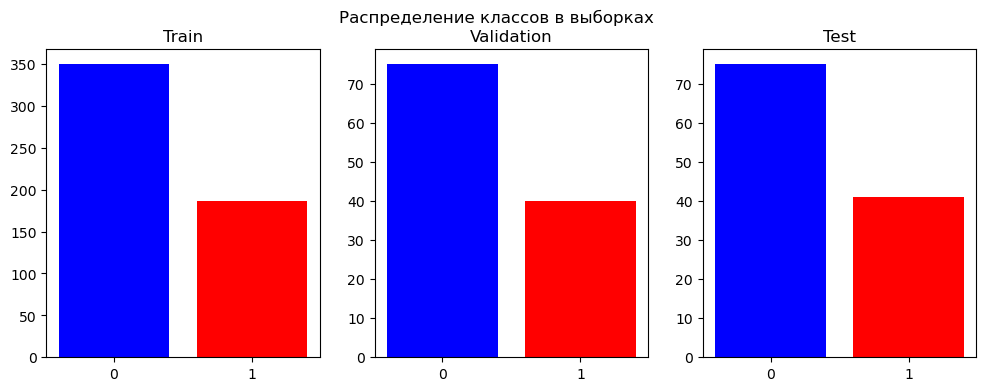

In [ ]:
# Разделение на признаки и целевую переменную
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

# Нормализация мёд по телу что это не нужно считать
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Разделение на train/val/test (70/15/15)
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Размеры выборок:")
print(f"Train: {X_train.shape}, {np.bincount(y_train)}")
print(f"Val:   {X_val.shape}, {np.bincount(y_val)}")
print(f"Test:  {X_test.shape}, {np.bincount(y_test)}")


plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.bar(['0', '1'], np.bincount(y_train), color=['blue', 'red'])
plt.title('Train')
plt.subplot(1, 3, 2)
plt.bar(['0', '1'], np.bincount(y_val), color=['blue', 'red'])
plt.title('Validation')
plt.subplot(1, 3, 3)
plt.bar(['0', '1'], np.bincount(y_test), color=['blue', 'red'])
plt.title('Test')
plt.suptitle('Распределение классов в выборках')
plt.show()

Функция для создания и обучения модели(ооп вновь проиграло муаххахахахахахахахаха)

In [59]:
def create_and_train_model(architecture, X_train, y_train, X_val, y_val):
    
    model = Sequential(name=architecture)
    
    if architecture == 'simple':
        # Простая: 2 скрытых слоя
        model.add(Dense(32, input_dim=8, activation='relu'))
        model.add(Dense(16, activation='relu'))
        
    elif architecture == 'deep':
        # Глубокая: 4 скрытых слоя
        model.add(Dense(64, input_dim=8, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(32, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(16, activation='relu'))
        model.add(Dense(8, activation='relu'))
        
    elif architecture == 'wide':
        # Широкая: один большой слой
        model.add(Dense(128, input_dim=8, activation='relu'))
        model.add(Dense(64, activation='relu'))
        model.add(Dense(32, activation='relu'))
    
    # Выходной слой (для бинарной классификации)
    model.add(Dense(1, activation='sigmoid'))
    
    # Компиляция
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    # Обучение
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)]
    )
    
    return model, history

ПРОСТАЯ

АРХИТЕКТУРА 1: ПРОСТАЯ (2 слоя: 32 -> 16)


C:\Users\Пользователь\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Тестовая точность: 0.7759 (77.59%)


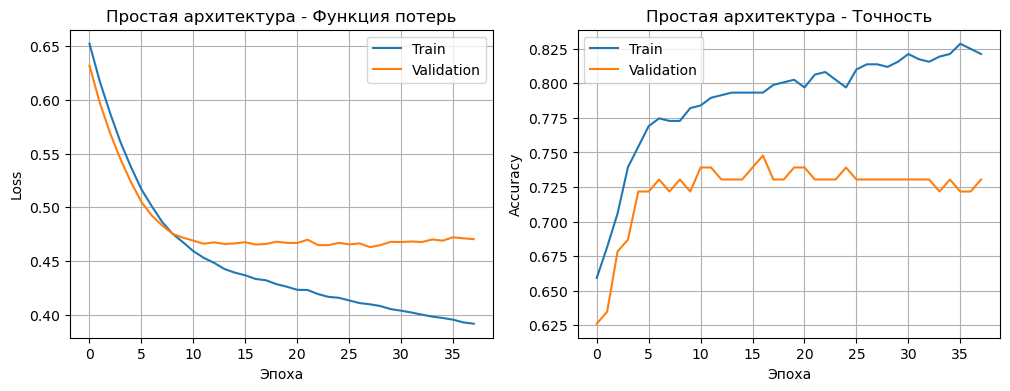

In [ ]:
print("="*60)
print("АРХИТЕКТУРА 1: ПРОСТАЯ (2 слоя: 32 -> 16)")
print("="*60)

model_simple, history_simple = create_and_train_model('simple', X_train, y_train, X_val, y_val)

# Оценка
loss_simple, acc_simple = model_simple.evaluate(X_test, y_test, verbose=0)
print(f"\nТестовая точность: {acc_simple:.4f} ({acc_simple*100:.2f}%)")


plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_simple.history['loss'], label='Train')
plt.plot(history_simple.history['val_loss'], label='Validation')
plt.title('Простая архитектура - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_simple.history['accuracy'], label='Train')
plt.plot(history_simple.history['val_accuracy'], label='Validation')
plt.title('Простая архитектура - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

глубокая архитектура , как синиццвет герба дгту

АРХИТЕКТУРА 2: ГЛУБОКАЯ (4 слоя: 64 -> 32 -> 16 -> 8 + Dropout)

Тестовая точность: 0.7500 (75.00%)


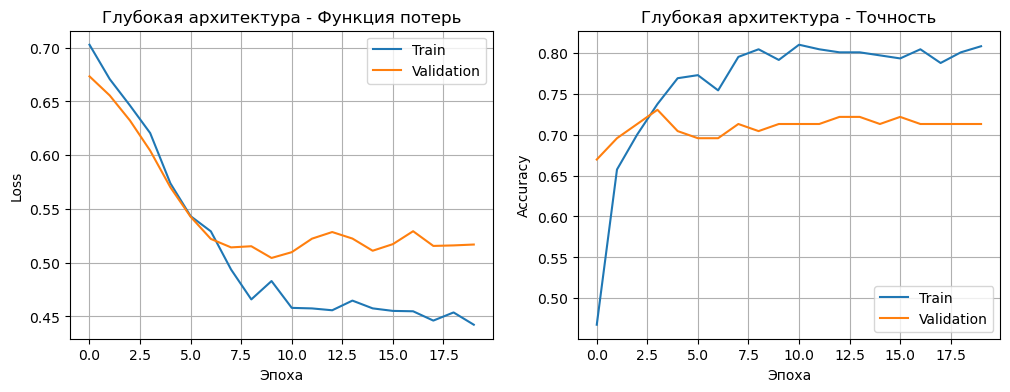

In [ ]:
print("="*60)
print("АРХИТЕКТУРА 2: ГЛУБОКАЯ (4 слоя: 64 -> 32 -> 16 -> 8 + Dropout)")
print("="*60)

model_deep, history_deep = create_and_train_model('deep', X_train, y_train, X_val, y_val)

# Оценка
loss_deep, acc_deep = model_deep.evaluate(X_test, y_test, verbose=0)
print(f"\nТестовая точность: {acc_deep:.4f} ({acc_deep*100:.2f}%)")


plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_deep.history['loss'], label='Train')
plt.plot(history_deep.history['val_loss'], label='Validation')
plt.title('Глубокая архитектура - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_deep.history['accuracy'], label='Train')
plt.plot(history_deep.history['val_accuracy'], label='Validation')
plt.title('Глубокая архитектура - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

ШИРОКУЮ НА ШИРОКУЮ

АРХИТЕКТУРА 3: ШИРОКАЯ (3 слоя: 128 -> 64 -> 32)

Тестовая точность: 0.7672 (76.72%)


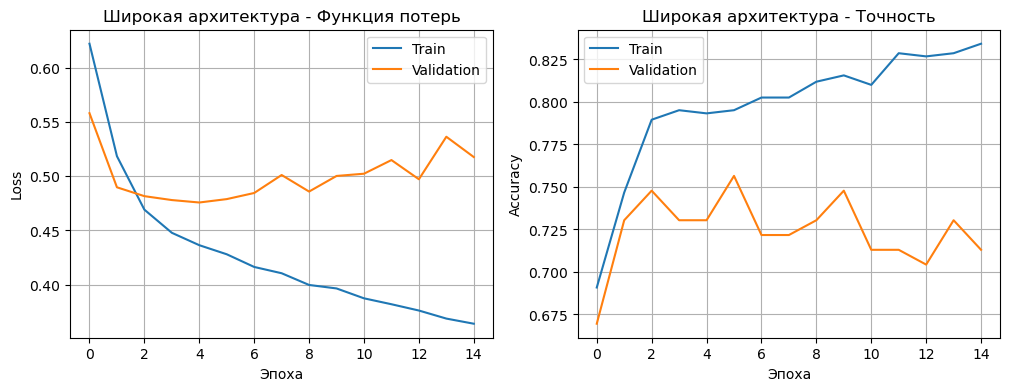

In [ ]:
print("="*60)
print("АРХИТЕКТУРА 3: ШИРОКАЯ (3 слоя: 128 -> 64 -> 32)")
print("="*60)

model_wide, history_wide = create_and_train_model('wide', X_train, y_train, X_val, y_val)

# Оценка
loss_wide, acc_wide = model_wide.evaluate(X_test, y_test, verbose=0)
print(f"\nТестовая точность: {acc_wide:.4f} ({acc_wide*100:.2f}%)")


plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_wide.history['loss'], label='Train')
plt.plot(history_wide.history['val_loss'], label='Validation')
plt.title('Широкая архитектура - Функция потерь')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_wide.history['accuracy'], label='Train')
plt.plot(history_wide.history['val_accuracy'], label='Validation')
plt.title('Широкая архитектура - Точность')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

Кто останеться в живых , будет завидовать мертвым 

СРАВНЕНИЕ ВСЕХ АРХИТЕКТУР
  Архитектура  Тестовая точность
0     Простая           0.775862
1    Глубокая           0.750000
2     Широкая           0.767241



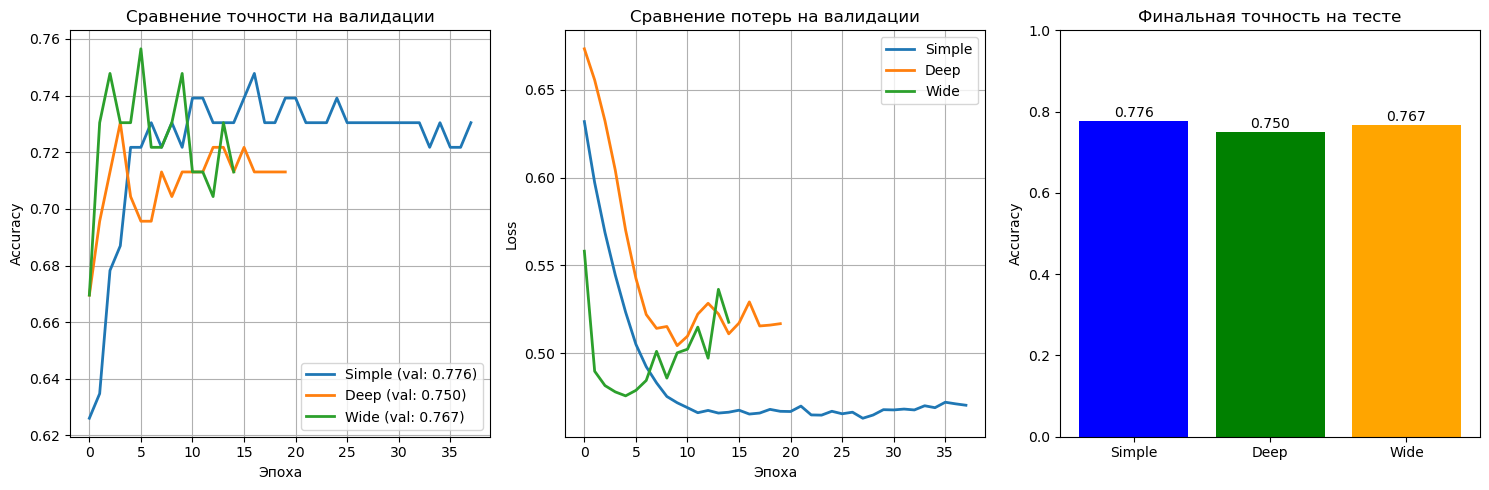

In [ ]:
print("="*60)
print("СРАВНЕНИЕ ВСЕХ АРХИТЕКТУР")
print("="*60)


results = pd.DataFrame({
    'Архитектура': ['Простая', 'Глубокая', 'Широкая'],
    'Тестовая точность': [acc_simple, acc_deep, acc_wide]
})
print(results)
print()


plt.figure(figsize=(15, 5))


plt.subplot(1, 3, 1)
plt.plot(history_simple.history['val_accuracy'], label=f'Simple (val: {acc_simple:.3f})', linewidth=2)
plt.plot(history_deep.history['val_accuracy'], label=f'Deep (val: {acc_deep:.3f})', linewidth=2)
plt.plot(history_wide.history['val_accuracy'], label=f'Wide (val: {acc_wide:.3f})', linewidth=2)
plt.title('Сравнение точности на валидации')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(history_simple.history['val_loss'], label='Simple', linewidth=2)
plt.plot(history_deep.history['val_loss'], label='Deep', linewidth=2)
plt.plot(history_wide.history['val_loss'], label='Wide', linewidth=2)
plt.title('Сравнение потерь на валидации')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)


plt.subplot(1, 3, 3)
bars = plt.bar(['Simple', 'Deep', 'Wide'], [acc_simple, acc_deep, acc_wide], 
               color=['blue', 'green', 'orange'])
plt.title('Финальная точность на тесте')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
for bar, acc in zip(bars, [acc_simple, acc_deep, acc_wide]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{acc:.3f}', ha='center')

plt.tight_layout()
plt.show()

ТЕСТИРОВАНИЕ НА СВОИХ ДАННЫХ
Введите значения для 8 признаков:
Ошибка! Введите число

РЕЗУЛЬТАТЫ ПРЕДСКАЗАНИЙ

Простая архитектура:
  Вероятность диабета: 0.0082
  Предсказание: 0 (Нет диабета)
  Уверенность: 99.18%

Глубокая архитектура:
  Вероятность диабета: 0.0022
  Предсказание: 0 (Нет диабета)
  Уверенность: 99.78%

Широкая архитектура:
  Вероятность диабета: 0.0090
  Предсказание: 0 (Нет диабета)
  Уверенность: 99.10%


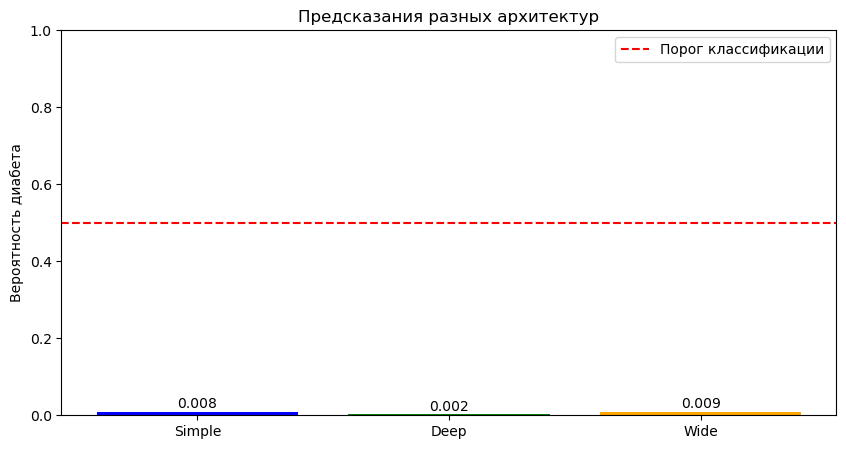


✅ Тестирование завершено!


In [ ]:
print("="*60)
print("ТЕСТИРОВАНИЕ НА СВОИХ ДАННЫХ")
print("="*60)
print("Введите значения для 8 признаков:")

# Сбор данных от пользователя
feature_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
                 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
user_data = []

for name in feature_names:
    while True:
        try:
            val = float(input(f"{name}: "))
            user_data.append(val)
            break
        except:
            print("Ошибка! Введите число")

# Нормализация
user_scaled = scaler.transform([user_data])

print("\n" + "="*60)
print("РЕЗУЛЬТАТЫ ПРЕДСКАЗАНИЙ")
print("="*60)

# Предсказания всех трех моделей
models = [
    (model_simple, "Простая архитектура"),
    (model_deep, "Глубокая архитектура"),
    (model_wide, "Широкая архитектура")
]

for model, name in models:
    prob = model.predict(user_scaled, verbose=0)[0][0]
    pred_class = 1 if prob >= 0.5 else 0
    
    print(f"\n{name}:")
    print(f"  Вероятность диабета: {prob:.4f}")
    print(f"  Предсказание: {pred_class} ({'Диабет' if pred_class == 1 else 'Нет диабета'})")
    print(f"  Уверенность: {prob if pred_class==1 else 1-prob:.2%}")


plt.figure(figsize=(10, 5))
probs = [model[0].predict(user_scaled, verbose=0)[0][0] for model in models]
names = ['Simple', 'Deep', 'Wide']

bars = plt.bar(names, probs, color=['blue', 'green', 'orange'])
plt.axhline(y=0.5, color='red', linestyle='--', label='Порог классификации')
plt.title('Предсказания разных архитектур')
plt.ylabel('Вероятность диабета')
plt.ylim(0, 1)

for bar, prob in zip(bars, probs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{prob:.3f}', ha='center')

plt.legend()
plt.show()

print("\n✅ Тестирование завершено!")

МАТРИЦЫ ОШИБОК НА ТЕСТОВОЙ ВЫБОРКЕ


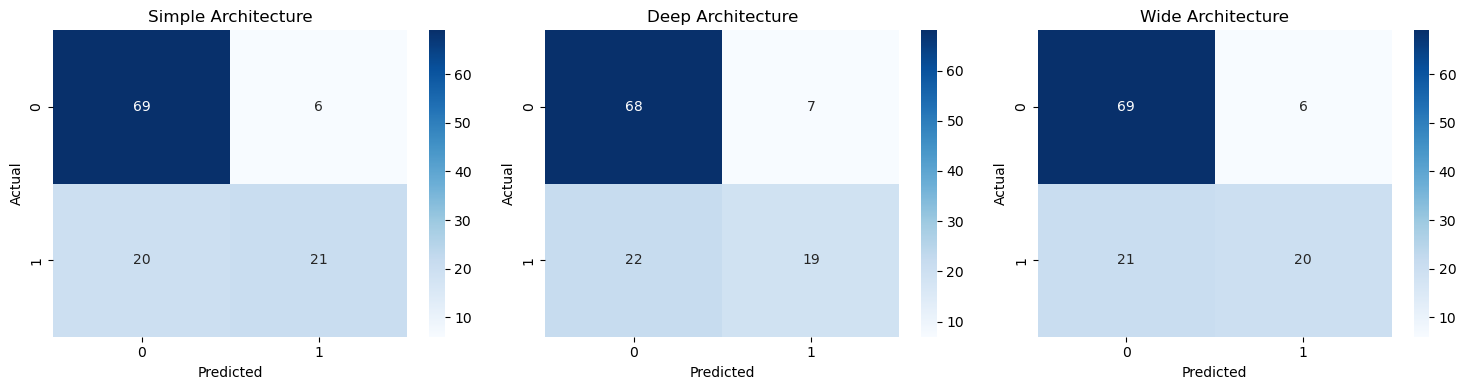

In [65]:
print("="*60)
print("МАТРИЦЫ ОШИБОК НА ТЕСТОВОЙ ВЫБОРКЕ")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (model, name) in enumerate([(model_simple, 'Simple'), (model_deep, 'Deep'), (model_wide, 'Wide')]):
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int)
    
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'{name} Architecture')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()